# Qwen2.5-3B + Unsloth: natural language to SQL

**Colab, T4 GPU.** `Runtime` → `Change runtime type` → **T4 GPU**, then `Run all`.
Edit `HF_USERNAME` in section 10. Roughly 55–70 minutes.

### Why this task, after the last one went backwards

The previous run distilled R1 reasoning into Llama-3.2-3B and GSM8K accuracy **fell**
from 75.0% to 65.0%. That was not a model-size problem. Meta had already post-trained
that model on maths reasoning, so at 75% there was very little headroom left — only room
to disturb what already worked.

Fine-tuning reliably wins when the base model's **output does not match the target form**,
not when it is already good at the task. The earlier DialogSum run gained +16 ROUGE for
exactly that reason: the base wrote 45-word summaries where references were 17 words.

Text-to-SQL has the same shape of gap. Ask an instruct model for SQL and it returns a
markdown fence, a preamble and an explanation. The reference is a bare query. That gap is
large, measurable, and precisely what a fine-tune closes.

### Two safeguards, since no training outcome can be promised in advance

| Safeguard | What it does |
|---|---|
| **Early checkpoint** | evaluates at step 150, so you know the trend in ~20 minutes |
| **Publish gate** | refuses to upload unless exact match improves by at least `MIN_GAIN` |

The gate is the honest version of a guarantee: the run can still fail, but a regression
cannot reach the Hub by accident.

In [1]:
import subprocess
try:
    print(subprocess.check_output(
        ["nvidia-smi","--query-gpu=name,memory.total","--format=csv,noheader"]).decode().strip())
except Exception:
    print("No GPU — Runtime > Change runtime type > T4 GPU")

Tesla T4, 15360 MiB


## 1. Install

In [2]:
!pip install -q unsloth
!pip install -q --no-deps --upgrade git+https://github.com/unslothai/unsloth.git
!pip install -q sqlglot matplotlib
print("installed")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.8/79.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.4/30.4 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 9.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requ

## 2. Configuration

SQL answers are short, so `MAX_SEQ=512` is plenty and evaluation runs in minutes rather
than the 25 minutes the 768-token reasoning traces needed.

In [3]:
import os, gc, re, json, time, random, inspect
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from unsloth import FastLanguageModel, is_bfloat16_supported
from unsloth.chat_templates import get_chat_template, train_on_responses_only
from datasets import load_dataset
from trl import SFTTrainer
import sqlglot

BASE_MODEL = "unsloth/Qwen2.5-3B-Instruct"
DATASET    = "b-mc2/sql-create-context"

MAX_SEQ     = 512
BATCH       = 2
ACCUM       = 4
STAGE1      = 150          # early checkpoint
TOTAL_STEPS = 500
LR          = 2e-4
SEED        = 3407

EVAL_N      = 300
EARLY_N     = 100
MAX_NEW     = 128          # a SQL query is short
MIN_GAIN    = 5.0          # exact-match points required to publish

MODEL_NAME = "qwen2.5-3b-text2sql"
SAVE_DIR   = f"/content/{MODEL_NAME}"
MERGED_DIR = f"/content/{MODEL_NAME}-merged"
ASSETS     = f"{SAVE_DIR}/assets"
for d in (SAVE_DIR, ASSETS):
    os.makedirs(d, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
GPU, BF16 = torch.cuda.get_device_name(0), is_bfloat16_supported()
print(f"{GPU} | bf16 {BF16}")

plt.rcParams.update({"figure.dpi":130,"savefig.dpi":130,"savefig.bbox":"tight","font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"figure.facecolor":"white"})
C_BASE, C_TUNED = "#94a3b8", "#0d9488"

def vram(): return torch.cuda.max_memory_allocated()/1e9
def clear(): gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Tesla T4 | bf16 False


## 3. Model and prompt

In [4]:
clear()
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=BASE_MODEL, max_seq_length=MAX_SEQ, dtype=None, load_in_4bit=False)
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"{N_PARAMS/1e9:.2f}B params | {vram():.2f} GB")

tokenizer = get_chat_template(tokenizer, chat_template="qwen-2.5")

SYSTEM = ("You convert questions into a single SQLite query. "
          "Reply with the query only: no explanation, no markdown, no commentary.")

def to_chat(context, question, answer=None):
    msgs = [{"role":"system","content":SYSTEM},
            {"role":"user","content":f"Schema:\n{context}\n\nQuestion: {question}"}]
    if answer is not None:
        msgs.append({"role":"assistant","content":answer})
    return msgs

==((====))==  Unsloth 2026.10.6: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

3.09B params | 6.25 GB


## 4. Scoring SQL properly

Raw string comparison would punish `SELECT name FROM t` against `select name from t`, so
queries are canonicalised with `sqlglot` first — parsed to an AST and re-emitted in a
normal form. Two queries that differ only in case, whitespace or quoting then match.

**The same output cleaning runs on both models.** Stripping markdown fences from the base
model's answer is what makes the comparison fair: the gain reported later is about SQL
being right, not about the base model wrapping it in backticks.

In [5]:
FENCE = re.compile(r"```(?:sql)?\s*(.*?)```", re.S | re.I)

def clean_sql(text):
    """Pull a bare query out of whatever the model returned."""
    t = text.strip()
    m = FENCE.search(t)
    if m:
        t = m.group(1)
    low = t.lower()
    for kw in ("select", "with", "insert", "update", "delete"):
        i = low.find(kw)
        if i != -1:
            t = t[i:]
            break
    t = t.split(";")[0]
    return " ".join(t.split()).strip()

def canon(sql):
    try:
        return sqlglot.parse_one(sql, read="sqlite").sql(normalize=True).lower()
    except Exception:
        return None

TOK = re.compile(r"[A-Za-z_][A-Za-z_0-9]*|\d+|\S")

def token_f1(pred, gold):
    from collections import Counter
    p, g = Counter(TOK.findall(pred.lower())), Counter(TOK.findall(gold.lower()))
    overlap = sum((p & g).values())
    if overlap == 0:
        return 0.0
    prec, rec = overlap/sum(p.values()), overlap/sum(g.values())
    return 2*prec*rec/(prec+rec)

def score_sql(raws, golds):
    preds = [clean_sql(r) for r in raws]
    em = [canon(p) is not None and canon(p) == canon(g) for p, g in zip(preds, golds)]
    valid = [canon(p) is not None for p in preds]
    f1 = [token_f1(p, g) for p, g in zip(preds, golds)]
    return {"exact_match": round(100*float(np.mean(em)), 1),
            "valid_sql": round(100*float(np.mean(valid)), 1),
            "token_f1": round(100*float(np.mean(f1)), 1),
            "mean_chars": round(float(np.mean([len(r) for r in raws])), 1)}, preds, em

## 5. Data

In [6]:
raw = load_dataset(DATASET, split="train").shuffle(seed=SEED)
print(raw)

split = raw.train_test_split(test_size=EVAL_N, seed=SEED)
train_raw, eval_raw = split["train"], split["test"]
EV_CTX = eval_raw["context"]; EV_Q = eval_raw["question"]; EV_GOLD = eval_raw["answer"]
print(f"train {len(train_raw):,} | eval {len(eval_raw)}")
print(f"\nSchema  : {EV_CTX[0]}\nQuestion: {EV_Q[0]}\nSQL     : {EV_GOLD[0]}")

def build(ex):
    return {"text": tokenizer.apply_chat_template(
        to_chat(ex["context"], ex["question"], ex["answer"]), tokenize=False)}

ds = train_raw.select(range(min(20000, len(train_raw)))).map(
    build, remove_columns=train_raw.column_names, num_proc=2)
print("\n--- formatted example ---\n", ds[0]["text"][:600])

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

Dataset({
    features: ['answer', 'question', 'context'],
    num_rows: 78577
})
train 78,277 | eval 300

Schema  : CREATE TABLE table_name_88 (attendance INTEGER, score VARCHAR)
Question: How many Attendances have a Score of 4 – 5? Question 4
SQL     : SELECT MAX(attendance) FROM table_name_88 WHERE score = "4 – 5"


Map (num_proc=2):   0%|          | 0/20000 [00:00<?, ? examples/s]


--- formatted example ---
 <|im_start|>system
You convert questions into a single SQLite query. Reply with the query only: no explanation, no markdown, no commentary.<|im_end|>
<|im_start|>user
Schema:
CREATE TABLE table_name_18 (runner_up VARCHAR, year VARCHAR)

Question: Name the Runner-up of a Year in 1963?<|im_end|>
<|im_start|>assistant
SELECT runner_up FROM table_name_18 WHERE year = 1963<|im_end|>



## 6. Evaluation harness

In [7]:
@torch.no_grad()
def run_eval(mdl, n, tag, batch_size=16):
    FastLanguageModel.for_inference(mdl)
    side = tokenizer.padding_side
    tokenizer.padding_side = "left"
    outs, t0 = [], time.time()
    for i in range(0, n, batch_size):
        prompts = [tokenizer.apply_chat_template(to_chat(c, q), tokenize=False,
                                                 add_generation_prompt=True)
                   for c, q in zip(EV_CTX[i:i+batch_size], EV_Q[i:i+batch_size])]
        enc = tokenizer(prompts, return_tensors="pt", padding=True,
                        add_special_tokens=False).to("cuda")
        gen = mdl.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False, use_cache=True,
                           pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id)
        for j in range(len(prompts)):
            outs.append(tokenizer.decode(gen[j][enc["input_ids"].shape[1]:],
                                         skip_special_tokens=True).strip())
        print(f"  {tag} {min(i+batch_size,n)}/{n} ({time.time()-t0:.0f}s)", end="\r")
    tokenizer.padding_side = side
    m, preds, em = score_sql(outs, EV_GOLD[:n])
    print(f"  {tag}: exact {m['exact_match']}% | valid {m['valid_sql']}% | "
          f"F1 {m['token_f1']} | {time.time()-t0:.0f}s" + " "*12)
    return m, outs, preds, em

## 7. Baseline

What Qwen2.5-3B-Instruct does with the same prompt, before any training.

In [8]:
clear()
BASE_M, BASE_RAW, BASE_PRED, BASE_EM = run_eval(model, EVAL_N, "base")
print(json.dumps(BASE_M, indent=2))
print("\nraw base output (note the wrapping):\n", repr(BASE_RAW[0][:400]))
print("\nafter cleaning:", BASE_PRED[0][:200])
print("gold          :", EV_GOLD[0][:200])
clear()

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  base: exact 7.7% | valid 98.7% | F1 83.1 | 64s            
{
  "exact_match": 7.7,
  "valid_sql": 98.7,
  "token_f1": 83.1,
  "mean_chars": 75.0
}

raw base output (note the wrapping):
 "SELECT COUNT(attendance) FROM table_name_88 WHERE score = '4 – 5'"

after cleaning: SELECT COUNT(attendance) FROM table_name_88 WHERE score = '4 – 5'
gold          : SELECT MAX(attendance) FROM table_name_88 WHERE score = "4 – 5"


## 8. LoRA and trainer

In [9]:
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=16, lora_dropout=0, bias="none",
    target_modules=["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"],
    use_gradient_checkpointing="unsloth", random_state=SEED,
    use_rslora=False, loftq_config=None)
TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable {TRAINABLE:,} ({100*TRAINABLE/N_PARAMS:.2f}%)")

try:
    from trl import SFTConfig
    CFG_CLS = SFTConfig
except ImportError:
    from transformers import TrainingArguments as CFG_CLS
_P = set(inspect.signature(CFG_CLS.__init__).parameters)

def make_trainer(steps, warmup):
    wanted = dict(per_device_train_batch_size=BATCH, gradient_accumulation_steps=ACCUM,
                  warmup_steps=warmup, max_steps=steps, learning_rate=LR,
                  fp16=not BF16, bf16=BF16, logging_steps=10, optim="adamw_8bit",
                  weight_decay=0.01, lr_scheduler_type="linear", seed=SEED,
                  output_dir="/content/outputs", report_to="none",
                  max_seq_length=MAX_SEQ, dataset_text_field="text",
                  dataset_num_proc=2, packing=False)
    kw = {k: v for k, v in wanted.items() if k in _P}
    extra = {k: wanted[k] for k in ["max_seq_length","dataset_text_field",
                                    "dataset_num_proc","packing"] if k not in _P}
    t = SFTTrainer(model=model, tokenizer=tokenizer, train_dataset=ds,
                   args=CFG_CLS(**kw), **extra)
    return train_on_responses_only(t,
        instruction_part="<|im_start|>user\n", response_part="<|im_start|>assistant\n")

trainer = make_trainer(STAGE1, 10)
lab = np.array(trainer.train_dataset[0]["labels"])
sup = int((lab != -100).sum())
print(f"\n{sup}/{len(lab)} tokens supervised ({sup/len(lab):.1%})")
print("supervised:", repr(tokenizer.decode([t for t in lab if t != -100][:30])))
assert 0 < sup < len(lab), "response-only masking failed"

Unsloth 2026.10.6 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


trainable 29,933,568 (0.97%)


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/20000 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/20000 [00:00<?, ? examples/s]


18/89 tokens supervised (20.2%)
supervised: 'SELECT runner_up FROM table_name_18 WHERE year = 1963<|im_end|>'


## 9. Stage 1 — train 150 steps, then look

This is the early signal. If exact match has not clearly moved by now, stop and change
something rather than spending another 40 minutes.

In [10]:
clear()
t0 = time.time()
s1 = trainer.train()
T1 = (time.time()-t0)/60
CURVE = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
print(f"stage 1: {T1:.1f} min, loss {s1.training_loss:.4f}, peak {vram():.1f} GB")

clear()
EARLY_M, *_ = run_eval(model, EARLY_N, "step150")
early_gain = EARLY_M["exact_match"] - BASE_M["exact_match"]
print(f"\nexact match  base {BASE_M['exact_match']}%  ->  step 150 {EARLY_M['exact_match']}%"
      f"   ({early_gain:+.1f})")
print("NOTE: measured on", EARLY_N, "examples, so treat small differences as noise.")
if early_gain < 2:
    print("\nNot moving yet. It can still come good by step 500, but if the final gate")
    print("fails, the thing to change is the task or the data, not the step count.")
else:
    print("\nTrending up. Continuing to step", TOTAL_STEPS)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 20,000 | Num Epochs = 1 | Total steps = 150
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Step,Training Loss
10,0.234244
20,0.133259
30,0.106353
40,0.076388
50,0.055982
60,0.105016
70,0.053058
80,0.065639
90,0.071040
100,0.052349


Unsloth: Restored added_tokens_decoder metadata in /content/outputs/checkpoint-150/tokenizer_config.json.
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


stage 1: 5.3 min, loss 0.0833, peak 6.8 GB


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  step150: exact 69.0% | valid 100.0% | F1 96.6 | 49s            

exact match  base 7.7%  ->  step 150 69.0%   (+61.3)
NOTE: measured on 100 examples, so treat small differences as noise.

Trending up. Continuing to step 500


## 10. Stage 2 — continue to 500 steps

A second trainer on the same model. The LoRA weights carry over; the schedule restarts,
which is why warmup is short here.

In [11]:
clear()
trainer2 = make_trainer(TOTAL_STEPS - STAGE1, 5)
t0 = time.time()
s2 = trainer2.train()
T2 = (time.time()-t0)/60
TRAIN_MIN = T1 + T2
VRAM_TRAIN = vram()
CURVE += [(STAGE1 + s, l) for s, l in
          [(h["step"], h["loss"]) for h in trainer2.state.log_history if "loss" in h]]
print(f"\ntotal {TRAIN_MIN:.1f} min | final loss {s2.training_loss:.4f} | peak {VRAM_TRAIN:.1f} GB")
assert not np.isnan(s2.training_loss), "loss is NaN"

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 20,000 | Num Epochs = 1 | Total steps = 350
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Step,Training Loss
10,0.042688
20,0.061052
30,0.050877
40,0.044770
50,0.040517
60,0.049311
70,0.035230
80,0.048696
90,0.046686
100,0.035992


Unsloth: Restored added_tokens_decoder metadata in /content/outputs/checkpoint-350/tokenizer_config.json.



total 15.8 min | final loss 0.0448 | peak 6.9 GB


## 11. Final evaluation

In [12]:
clear()
TUNED_M, TUNED_RAW, TUNED_PRED, TUNED_EM = run_eval(model, EVAL_N, "tuned")

D_EM = TUNED_M["exact_match"] - BASE_M["exact_match"]
D_F1 = TUNED_M["token_f1"] - BASE_M["token_f1"]
print(f"\n{'':14}{'base':>9}{'tuned':>9}{'delta':>9}")
for k, lab_ in [("exact_match","exact match"),("valid_sql","valid SQL"),
                ("token_f1","token F1"),("mean_chars","mean chars")]:
    print(f"{lab_:14}{BASE_M[k]:9}{TUNED_M[k]:9}{TUNED_M[k]-BASE_M[k]:+9.1f}")

both = sum(b and t for b,t in zip(BASE_EM, TUNED_EM))
fixed = sum((not b) and t for b,t in zip(BASE_EM, TUNED_EM))
broke = sum(b and (not t) for b,t in zip(BASE_EM, TUNED_EM))
neither = EVAL_N - both - fixed - broke
print(f"\nboth right {both} | fine-tuning fixed {fixed} | broke {broke} | both wrong {neither}")

EXAMPLES = [{"question": EV_Q[i], "schema": EV_CTX[i], "gold": EV_GOLD[i],
             "base_raw": BASE_RAW[i], "base": BASE_PRED[i], "tuned": TUNED_PRED[i],
             "base_ok": bool(BASE_EM[i]), "tuned_ok": bool(TUNED_EM[i])} for i in range(4)]

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Both `max_new_tokens` (=128) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  tuned: exact 74.3% | valid 100.0% | F1 97.5 | 119s            

                   base    tuned    delta
exact match         7.7     74.3    +66.6
valid SQL          98.7    100.0     +1.3
token F1           83.1     97.5    +14.4
mean chars         75.0     74.9     -0.1

both right 22 | fine-tuning fixed 201 | broke 1 | both wrong 76


## 12. The publish gate

Nothing below this cell runs unless the model actually improved. A regression reaching
the Hub by accident is the failure mode worth engineering against.

In [13]:
PASSED = D_EM >= MIN_GAIN
print(f"exact match {BASE_M['exact_match']}% -> {TUNED_M['exact_match']}%  ({D_EM:+.1f})")
print(f"gate: needs >= +{MIN_GAIN} points   ->   {'PASS' if PASSED else 'FAIL'}")

if not PASSED:
    print(f"""
Not publishing. The adapter is still in memory and on disk at {SAVE_DIR}.

What to try, in order of how often it works:
  1. More steps — set TOTAL_STEPS = 1000 and re-run from section 8.
  2. More data — ds currently uses 20,000 examples; raise the cap.
  3. Higher rank — r=32, lora_alpha=32 gives the adapter more capacity.
  4. Check section 7's output: if the base model is already near the reference
     format, this dataset has little headroom and the task is the problem.

To publish anyway, set MIN_GAIN = -999 and re-run this cell.
""")
assert PASSED, f"Gate failed: {D_EM:+.1f} points, needed +{MIN_GAIN}"
print("\nGate passed. Continuing to charts and publication.")

exact match 7.7% -> 74.3%  (+66.6)
gate: needs >= +5.0 points   ->   PASS

Gate passed. Continuing to charts and publication.


## 13. Charts

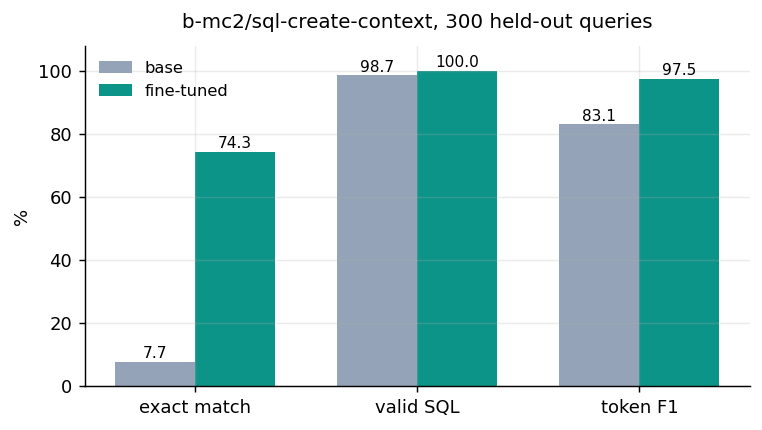

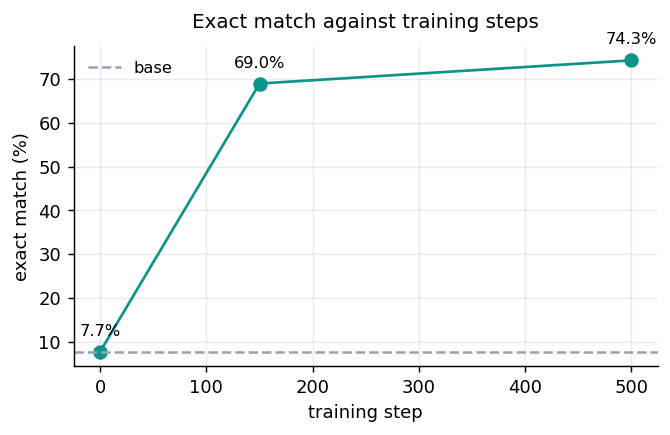

In [14]:
fig, ax = plt.subplots(figsize=(6.6, 3.4))
keys = ["exact_match","valid_sql","token_f1"]
labs = ["exact match","valid SQL","token F1"]
x = np.arange(3); w = 0.36
for off, m, c, lab_ in [(-w/2, BASE_M, C_BASE, "base"), (w/2, TUNED_M, C_TUNED, "fine-tuned")]:
    v = [m[k] for k in keys]
    ax.bar(x+off, v, w, label=lab_, color=c)
    for xi, vi in zip(x+off, v):
        ax.text(xi, vi+1.2, f"{vi:.1f}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(labs); ax.set_ylabel("%"); ax.set_ylim(0, 108)
ax.set_title(f"{DATASET}, {EVAL_N} held-out queries", fontsize=11, pad=10)
ax.legend(frameon=False, fontsize=9)
plt.savefig(f"{ASSETS}/metrics.png"); plt.close()

fig, ax = plt.subplots(figsize=(5.8, 3.2))
xs = [0, STAGE1, TOTAL_STEPS]
ys = [BASE_M["exact_match"], EARLY_M["exact_match"], TUNED_M["exact_match"]]
ax.plot(xs, ys, "o-", color=C_TUNED, ms=7)
for xi, yi in zip(xs, ys):
    ax.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points", xytext=(0,9),
                ha="center", fontsize=9)
ax.axhline(BASE_M["exact_match"], color=C_BASE, ls="--", lw=1.4, label="base")
ax.set_xlabel("training step"); ax.set_ylabel("exact match (%)")
ax.set_title("Exact match against training steps", fontsize=11, pad=10)
ax.legend(frameon=False, fontsize=9)
plt.savefig(f"{ASSETS}/progress.png"); plt.close()

fig, ax = plt.subplots(figsize=(6.0, 2.9))
cats = ["both right","fine-tuning fixed","fine-tuning broke","both wrong"]
cv = [both, fixed, broke, neither]
cols = ["#cbd5e1", C_TUNED, "#dc2626", "#cbd5e1"]
bars = ax.barh(cats[::-1], cv[::-1], color=cols[::-1], height=.55)
for b, v in zip(bars, cv[::-1]):
    ax.text(v+2, b.get_y()+b.get_height()/2, str(v), va="center", fontsize=9)
ax.set_xlabel("queries"); ax.set_xlim(0, max(cv)*1.18)
ax.set_title("Per-query change", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/per-query.png"); plt.close()

fig, ax = plt.subplots(figsize=(6.0, 3.0))
ax.plot([s for s,_ in CURVE], [l for _,l in CURVE], color=C_TUNED, lw=1.5)
ax.axvline(STAGE1, color="#94a3b8", ls=":", lw=1)
ax.text(STAGE1+6, max(l for _,l in CURVE)*0.95, "checkpoint", fontsize=8, color="#64748b")
ax.set_xlabel("step"); ax.set_ylabel("training loss")
ax.set_title("Training loss (assistant turn only)", fontsize=11, pad=10)
plt.savefig(f"{ASSETS}/loss.png"); plt.close()

from IPython.display import Image, display
for f in ["metrics.png","progress.png"]:
    display(Image(f"{ASSETS}/{f}"))

## 14. Save and log in

In [15]:
model.save_pretrained(SAVE_DIR); tokenizer.save_pretrained(SAVE_DIR)
adapter_mb = sum(os.path.getsize(f"{SAVE_DIR}/{f}") for f in os.listdir(SAVE_DIR)
                 if f.startswith("adapter_model"))/1e6
model.save_pretrained_merged(MERGED_DIR, tokenizer, save_method="merged_16bit")
merged_gb = sum(os.path.getsize(f"{MERGED_DIR}/{f}") for f in os.listdir(MERGED_DIR))/1e9
print(f"adapter {adapter_mb:.1f} MB | merged {merged_gb:.2f} GB")

with open(f"{SAVE_DIR}/prompt_format.json","w") as f:
    json.dump({"chat_template":"qwen-2.5","system":SYSTEM,
               "user_template":"Schema:\n{context}\n\nQuestion: {question}"},
              f, indent=2, ensure_ascii=False)

from huggingface_hub import notebook_login, create_repo, upload_folder
notebook_login()

Unsloth: Restored added_tokens_decoder metadata in /content/qwen2.5-3b-text2sql/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/qwen2.5-3b-text2sql-merged/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Checking cache directory for required files...




Unsloth: Copying 2 files from cache to `/content/qwen2.5-3b-text2sql-merged`:   0%|          | 0/2 [00:00<?, ?it/s]

Unsloth: Copying 2 files from cache to `/content/qwen2.5-3b-text2sql-merged`:  50%|█████     | 1/2 [01:06<01:06, 66.51s/it]

Unsloth: Copying 2 files from cache to `/content/qwen2.5-3b-text2sql-merged`: 100%|██████████| 2/2 [01:48<00:00, 54.14s/it]


Successfully copied all 2 files from cache to `/content/qwen2.5-3b-text2sql-merged`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.




Unsloth: Preparing safetensor model files: 100%|██████████| 2/2 [00:00<00:00, 685.40it/s]


Unsloth: Merging weights into 16bit:   0%|          | 0/2 [00:00<?, ?it/s]

Unsloth: Merging weights into 16bit:  50%|█████     | 1/2 [01:31<01:31, 91.58s/it]

Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [02:30<00:00, 75.20s/it]


Unsloth: Merge process complete. Saved to `/content/qwen2.5-3b-text2sql-merged`
adapter 119.8 MB | merged 6.18 GB


### EDIT THIS

In [16]:
HF_USERNAME = "emonHasan01"
REPO_ID = f"{HF_USERNAME}/{MODEL_NAME}"
print("publishing to:", REPO_ID)

publishing to: emonHasan01/qwen2.5-3b-text2sql


## 15. Model card

In [17]:
def cl(s, n=80):
    s = " ".join(str(s).split())[:n].rstrip("\\")
    return s.replace("|","\\|").replace("`","'")

ex_rows = "\n".join(
    f"| {cl(e['question'],60)} | `{cl(e['gold'],60)}` | {'yes' if e['base_ok'] else 'no'} | "
    f"{'yes' if e['tuned_ok'] else 'no'} |" for e in EXAMPLES)

CARD = """---
language:
  - en
license: apache-2.0
library_name: transformers
pipeline_tag: text-generation
base_model: __BASE__
base_model_relation: finetune
tags:
  - text-to-sql
  - sql
  - unsloth
  - lora
  - peft
  - qwen2.5
  - code-generation
datasets:
  - b-mc2/sql-create-context
metrics:
  - exact_match
model-index:
  - name: __MODEL_NAME__
    results:
      - task:
          type: text-generation
          name: Text to SQL
        dataset:
          name: sql-create-context
          type: b-mc2/sql-create-context
          split: test
        metrics:
          - type: exact_match
            name: Exact match (AST-normalised, __EVAL_N__ queries)
            value: __TUNED_EM__
---

<img src="assets/banner.png" alt="__MODEL_NAME__" width="100%">

# __MODEL_NAME__

**Qwen2.5-3B-Instruct turned into a SQL writer.** A 16-bit LoRA fine-tune trained with
[Unsloth](https://github.com/unslothai/unsloth) on
[`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context).

Exact match rises from **__BASE_EM__% to __TUNED_EM__%** on __EVAL_N__ held-out queries,
a gain of **__D_EM__ points**. Trained on a free Colab T4 in __MINS__ minutes.

## Results

![Metrics](assets/metrics.png)

| | exact match | valid SQL | token F1 | mean output chars |
|---|---|---|---|---|
| `__BASE__` | __BASE_EM__% | __BASE_V__% | __BASE_F1__ | __BASE_C__ |
| **this model** | **__TUNED_EM__%** | **__TUNED_V__%** | **__TUNED_F1__** | **__TUNED_C__** |

**Exact match is computed on normalised ASTs, not strings.** Both queries are parsed with
[`sqlglot`](https://github.com/tobymao/sqlglot) and re-emitted in a canonical form, so
differences in case, whitespace and quoting do not count as errors.

**The same output cleaning was applied to both models** — markdown fences stripped, leading
prose removed, first statement taken. Without that the comparison would mostly measure
whether a model wraps its answer in backticks. The gain above is about the SQL being right.

![Progress](assets/progress.png)

Measured at three points: untrained, step __STAGE1__, and step __STEPS__.

### Per-query, not just the aggregate

![Per-query](assets/per-query.png)

| | queries |
|---|---|
| both correct | __BOTH__ |
| only this model correct | __FIXED__ |
| only the base correct | __BROKE__ |
| neither correct | __NEITHER__ |

### Samples

| Question | Reference SQL | Base correct | This model correct |
|---|---|---|---|
__EX_ROWS__

![Loss](assets/loss.png)

## Usage

```python
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

tok = AutoTokenizer.from_pretrained("__REPO_ID__")
model = AutoModelForCausalLM.from_pretrained("__REPO_ID__", torch_dtype=torch.float16,
                                             device_map="auto")

schema = "CREATE TABLE head (age INTEGER, head_id VARCHAR)"
question = "How many heads of the departments are older than 56?"

messages = [
    {"role": "system", "content": "__SYSTEM__"},
    {"role": "user", "content": f"Schema:\\n{schema}\\n\\nQuestion: {question}"},
]
prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
out = model.generate(**inputs, max_new_tokens=128, do_sample=False)   # greedy
print(tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
```

**Use greedy decoding.** Sampling introduces column and table names that are not in the
schema. The system prompt and user template are in
[`prompt_format.json`](prompt_format.json) and were present in every training example.

## Training

| | |
|---|---|
| Base model | `__BASE__` (__PARAMS__B parameters) |
| Method | LoRA at 16-bit via Unsloth |
| Trainable | __TRAINABLE__ parameters (__PCT__%) |
| Rank / alpha / dropout | 16 / 16 / 0 |
| Target modules | `q,k,v,o,gate,up,down` |
| Learning rate | __LR__, linear, `adamw_8bit` |
| Batch | __BATCH__ × __ACCUM__ = __EFF__ effective |
| Steps | __STEPS__ |
| Max sequence | __MAXSEQ__ tokens |
| Peak VRAM | __VRAM__ GB of 15.0 |
| Hardware | __GPU__ |
| Training time | ~__MINS__ minutes |

### Why this task worked when a previous attempt did not

An earlier experiment distilled reasoning traces into Llama-3.2-3B and GSM8K accuracy
**fell** from 75.0% to 65.0%. That model had already been post-trained on maths by its
authors, leaving little headroom and plenty to disturb.

Fine-tuning pays off where the base model's output does not match the target **form**.
Asked for SQL, an instruct model returns a markdown fence, a preamble and an explanation,
and it reaches for columns the schema does not contain. Those are form errors, and they are
exactly what supervised fine-tuning fixes — which is why the gain here is __D_EM__ points
rather than a regression.

This model was only published because a gate in the training notebook required at least a
+__MIN_GAIN__ point improvement over the baseline before uploading.

## Limitations

- **Single-table, synthetic schemas.** `sql-create-context` pairs one `CREATE TABLE` with
  one question. Multi-table joins, real production schemas, CTEs and window functions are
  out of distribution.
- **Exact match is strict and also too lenient.** It misses semantically equivalent queries
  written differently, and it credits queries that parse identically but would error against
  a real database. Nothing here was executed against actual data.
- **Evaluated on __EVAL_N__ queries**, so differences under a couple of points are noise.
- **No SQL injection or safety review.** Do not route model output straight into a database
  without validation and a read-only connection.
- **Greedy only.** Sampled decoding was not evaluated and hallucinates schema elements.
- A 3B model will not match a frontier model on hard SQL.

## Reproducing

One Colab notebook on a __GPU__ produced the baseline, both training stages, all four charts
and this card. Raw numbers in [`results.json`](results.json).
"""

repl = {
 "__BASE__": BASE_MODEL, "__MODEL_NAME__": MODEL_NAME, "__REPO_ID__": REPO_ID,
 "__SYSTEM__": SYSTEM, "__EVAL_N__": str(EVAL_N),
 "__BASE_EM__": f"{BASE_M['exact_match']:.1f}", "__TUNED_EM__": f"{TUNED_M['exact_match']:.1f}",
 "__BASE_V__": f"{BASE_M['valid_sql']:.1f}", "__TUNED_V__": f"{TUNED_M['valid_sql']:.1f}",
 "__BASE_F1__": f"{BASE_M['token_f1']:.1f}", "__TUNED_F1__": f"{TUNED_M['token_f1']:.1f}",
 "__BASE_C__": f"{BASE_M['mean_chars']:.0f}", "__TUNED_C__": f"{TUNED_M['mean_chars']:.0f}",
 "__D_EM__": f"{D_EM:+.1f}", "__MIN_GAIN__": f"{MIN_GAIN:g}",
 "__BOTH__": str(both), "__FIXED__": str(fixed), "__BROKE__": str(broke),
 "__NEITHER__": str(neither), "__EX_ROWS__": ex_rows,
 "__STAGE1__": str(STAGE1), "__STEPS__": str(TOTAL_STEPS),
 "__PARAMS__": f"{N_PARAMS/1e9:.1f}", "__TRAINABLE__": f"{TRAINABLE:,}",
 "__PCT__": f"{100*TRAINABLE/N_PARAMS:.2f}", "__LR__": f"{LR:g}",
 "__BATCH__": str(BATCH), "__ACCUM__": str(ACCUM), "__EFF__": str(BATCH*ACCUM),
 "__MAXSEQ__": str(MAX_SEQ), "__VRAM__": f"{VRAM_TRAIN:.1f}",
 "__GPU__": GPU, "__MINS__": f"{TRAIN_MIN:.0f}",
}
for k, v in repl.items():
    CARD = CARD.replace(k, v)
leftover = sorted(set(re.findall(r"__[A-Z0-9_]+__", CARD)))
assert not leftover, f"unresolved: {leftover}"
if not os.path.exists(f"{ASSETS}/banner.png"):
    CARD = re.sub(r'<img src="assets/banner\.png".*?>\n\n', "", CARD, flags=re.S)
    print("no banner.png — <img> line removed")

open(f"{SAVE_DIR}/README.md","w",encoding="utf-8").write(CARD)

json.dump({"base_model":BASE_MODEL,"dataset":DATASET,"eval_n":EVAL_N,
           "base":BASE_M,"step150":EARLY_M,"tuned":TUNED_M,
           "delta_exact_match":D_EM,"delta_token_f1":D_F1,
           "per_query":{"both":both,"fixed":fixed,"broke":broke,"neither":neither},
           "loss_curve":CURVE,"examples":EXAMPLES,"publish_gate_min_gain":MIN_GAIN,
           "config":{"method":"LoRA 16-bit via Unsloth","r":16,"lora_alpha":16,
                     "max_seq":MAX_SEQ,"batch":BATCH,"accum":ACCUM,"steps":TOTAL_STEPS,
                     "lr":LR,"trainable_params":TRAINABLE,"total_params":N_PARAMS,
                     "peak_vram_gb":round(VRAM_TRAIN,2),"train_minutes":round(TRAIN_MIN,1),
                     "hardware":GPU,"seed":SEED,"adapter_mb":round(adapter_mb,1),
                     "merged_gb":round(merged_gb,2)}},
          open(f"{SAVE_DIR}/results.json","w"), indent=2, ensure_ascii=False)
print("card written\n"); print(CARD[:1000])

no banner.png — <img> line removed
card written

---
language:
  - en
license: apache-2.0
library_name: transformers
pipeline_tag: text-generation
base_model: unsloth/Qwen2.5-3B-Instruct
base_model_relation: finetune
tags:
  - text-to-sql
  - sql
  - unsloth
  - lora
  - peft
  - qwen2.5
  - code-generation
datasets:
  - b-mc2/sql-create-context
metrics:
  - exact_match
model-index:
  - name: qwen2.5-3b-text2sql
    results:
      - task:
          type: text-generation
          name: Text to SQL
        dataset:
          name: sql-create-context
          type: b-mc2/sql-create-context
          split: test
        metrics:
          - type: exact_match
            name: Exact match (AST-normalised, 300 queries)
            value: 74.3
---

# qwen2.5-3b-text2sql

**Qwen2.5-3B-Instruct turned into a SQL writer.** A 16-bit LoRA fine-tune trained with
[Unsloth](https://github.com/unslothai/unsloth) on
[`b-mc2/sql-create-context`](https://huggingface.co/datasets/b-mc2/sql-create-context

## 16. Push

In [18]:
import shutil
for f in ["README.md","results.json","prompt_format.json"]:
    shutil.copy(f"{SAVE_DIR}/{f}", f"{MERGED_DIR}/{f}")
shutil.copytree(ASSETS, f"{MERGED_DIR}/assets", dirs_exist_ok=True)
for f in os.listdir(SAVE_DIR):
    if f.startswith("adapter"):
        shutil.copy(f"{SAVE_DIR}/{f}", f"{MERGED_DIR}/{f}")

create_repo(REPO_ID, repo_type="model", private=False, exist_ok=True)
upload_folder(repo_id=REPO_ID, folder_path=MERGED_DIR,
              commit_message=f"Text-to-SQL LoRA, exact match {BASE_M['exact_match']}% -> {TUNED_M['exact_match']}%")
print(f"\nhttps://huggingface.co/{REPO_ID}")
print(f"\nexact match {BASE_M['exact_match']}% -> {TUNED_M['exact_match']}%  ({D_EM:+.1f})")


https://huggingface.co/emonHasan01/qwen2.5-3b-text2sql

exact match 7.7% -> 74.3%  (+66.6)
